# TopGAE on hESC TF overexpression (TFAtlas; Fig. 4B-C, Fig. S6B-C, Table S3)

1. **Subset** the TFAtlas ORF screen (GSE217460) to TFs present in the hESC ChIP-seq prior (`RN203.tsv`) with at least 100 cells, plus the GFP and mCherry controls -> `perturb/adata_orf.h5ad` (36 TFs).
2. **DE**: Wilcoxon test of each TF vs. GFP and vs. mCherry (Scanpy) -> `perturb/de_table_orf_gfp.csv`, `perturb/de_table_orf_mcherry.csv`.
3. **Training**: TopGAE is trained on control cells with the ChIP-seq prior, five seeds (42-46), first with GFP and then with mCherry as the control (cells marked `# GFP` / `# mCherry`).

Expected inputs in `perturb/`: `RN203.tsv` and `GSE217460_210322_TFAtlas_subsample_raw.h5ad` (gunzipped GEO download). Results are written to `perturb/perturb_orf_gfp_validation/` and `perturb/perturb_orf_mCherry_validation/`.

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scanpy as sc

In [2]:
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'

In [3]:
adata = sc.read_h5ad("perturb/GSE217460_210322_TFAtlas_subsample_raw.h5ad")
adata

AnnData object with n_obs × n_vars = 671453 × 37528
    obs: 'TF', 'batch', 'louvain', 'n_counts', 'n_genes', 'percent_mito', 'batchTF', 'score', 'temp', 'dpt_pseudotime', 'm3_pseudotime'

In [5]:
adata.obs['TF'].str.split('-').str[1].unique()

array(['DLX4', 'POU2F2', 'ZNF160', ..., 'ZNF551', 'ZNF699', 'ZNF765'],
      shape=(1714,), dtype=object)

In [6]:
adata.obs['TF'].unique()

['TFORF3021-DLX4', 'TFORF1864-POU2F2', 'TFORF1544-ZNF160', 'TFORF2641-PAX3', 'TFORF1594-ZNF197', ..., 'TFORF1719-ZNF699', 'TFORF0555-ZNF613', 'TFORF0211-FOXP3', 'TFORF1742-ZNF765', 'TFORF3469-ZNF438']
Length: 3266
Categories (3266, object): ['TFORF0001-HIF3A', 'TFORF0002-HIF3A', 'TFORF0003-HIF3A', 'TFORF0004-HIF3A', ..., 'TFORF3547-CBFB', 'TFORF3548-THAP10', 'TFORF3549-GFP', 'TFORF3550-mCherry']

In [3]:
net = pd.read_csv("perturb/RN203.tsv", sep="\t")
net

,Source,Target,Relationship
0,ASH2L,A1BG-AS1,Transcriptional_Regulation
1,ASH2L,A3GALT2,Transcriptional_Regulation
2,ASH2L,AAAS,Transcriptional_Regulation
3,ASH2L,AACS,Transcriptional_Regulation
4,ASH2L,AADACL4,Transcriptional_Regulation
...,...,...,...
822470,ZNF274,ZNF93,Transcriptional_Regulation
822471,ZNF274,ZNF98,Transcriptional_Regulation
822472,ZNF274,ZNF99,Transcriptional_Regulation
822473,ZNF274,ZRANB3,Transcriptional_Regulation


In [4]:
meta = adata.obs.copy()
meta['TF'] = meta['TF'].str.split('-').str[1]
meta = meta[meta['TF'].isin(net['Source'].tolist() + ['GFP', 'mCherry'])]
meta = meta[meta['TF'].map(meta['TF'].value_counts()) >= 100]
meta

,TF,batch,louvain,n_counts,n_genes,percent_mito,batchTF,score,temp,dpt_pseudotime,m3_pseudotime
"R1.01,R2.51,R3.39,P1.32-1-4-0",ATF3,0,2,1093.0,905,0.021043,10,1.761244,TFORF0799-ATF3,0.014083,0.502188
"R1.94,R2.06,R3.07,P1.15-3-1-0",ATF3,0,1,4109.0,2639,0.022147,10,-0.086042,TFORF0799-ATF3,0.011332,0.037688
"R1.56,R2.56,R3.77,P1.62-1-1-0",ATF3,0,1,3267.0,2238,0.024793,10,0.333905,TFORF0799-ATF3,0.010787,0.114548
"R1.59,R2.89,R3.90,P1.22-0-0",ATF3,0,0,2166.0,1625,0.020314,10,1.151119,TFORF0799-ATF3,0.012976,0.452694
"R1.32,R2.85,R3.25,P1.30-0-0",ATF3,0,1,1676.0,1328,0.029236,10,0.253499,TFORF0799-ATF3,0.010843,0.203199
...,...,...,...,...,...,...,...,...,...,...,...
"R1.72,R2.15,R3.54,P1.48-3-4-0",TCF12,0,0,3033.0,2168,0.023409,3215,0.271430,TFORF2248-TCF12,0.011570,0.366188
"R1.75,R2.34,R3.04,P1.48-3-4-0",TCF12,0,4,1927.0,1501,0.023352,3215,1.541606,TFORF2248-TCF12,0.032361,0.505021
"R1.76,R2.67,R3.49,P1.48-3-4-0",TCF12,0,0,2784.0,1988,0.024425,3215,0.000844,TFORF2248-TCF12,0.012197,0.156662
"R1.89,R2.88,R3.34,P1.48-3-4-0",TCF12,0,3,1906.0,1487,0.017838,3215,0.553693,TFORF2248-TCF12,0.010951,0.137479


In [5]:
adata_test = adata[meta.index, :].copy()
adata_test

AnnData object with n_obs × n_vars = 36819 × 37528
    obs: 'TF', 'batch', 'louvain', 'n_counts', 'n_genes', 'percent_mito', 'batchTF', 'score', 'temp', 'dpt_pseudotime', 'm3_pseudotime'

In [6]:
df_genes = set(net["Source"]).union(set(net["Target"]))
common_genes = df_genes.intersection(set(adata_test.var.index))
len(common_genes)

23413

In [7]:
concat = adata_test[:, adata_test.var.index.isin(common_genes)]
concat.obs['TF'] = concat.obs['TF'].str.split('-').str[1]
concat

/tmp/ipykernel_1920162/1204685662.py:2: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  concat.obs['TF'] = concat.obs['TF'].str.split('-').str[1]


AnnData object with n_obs × n_vars = 36819 × 23413
    obs: 'TF', 'batch', 'louvain', 'n_counts', 'n_genes', 'percent_mito', 'batchTF', 'score', 'temp', 'dpt_pseudotime', 'm3_pseudotime'

In [8]:
concat.obs

,TF,batch,louvain,n_counts,n_genes,percent_mito,batchTF,score,temp,dpt_pseudotime,m3_pseudotime
"R1.01,R2.51,R3.39,P1.32-1-4-0",ATF3,0,2,1093.0,905,0.021043,10,1.761244,TFORF0799-ATF3,0.014083,0.502188
"R1.94,R2.06,R3.07,P1.15-3-1-0",ATF3,0,1,4109.0,2639,0.022147,10,-0.086042,TFORF0799-ATF3,0.011332,0.037688
"R1.56,R2.56,R3.77,P1.62-1-1-0",ATF3,0,1,3267.0,2238,0.024793,10,0.333905,TFORF0799-ATF3,0.010787,0.114548
"R1.59,R2.89,R3.90,P1.22-0-0",ATF3,0,0,2166.0,1625,0.020314,10,1.151119,TFORF0799-ATF3,0.012976,0.452694
"R1.32,R2.85,R3.25,P1.30-0-0",ATF3,0,1,1676.0,1328,0.029236,10,0.253499,TFORF0799-ATF3,0.010843,0.203199
...,...,...,...,...,...,...,...,...,...,...,...
"R1.72,R2.15,R3.54,P1.48-3-4-0",TCF12,0,0,3033.0,2168,0.023409,3215,0.271430,TFORF2248-TCF12,0.011570,0.366188
"R1.75,R2.34,R3.04,P1.48-3-4-0",TCF12,0,4,1927.0,1501,0.023352,3215,1.541606,TFORF2248-TCF12,0.032361,0.505021
"R1.76,R2.67,R3.49,P1.48-3-4-0",TCF12,0,0,2784.0,1988,0.024425,3215,0.000844,TFORF2248-TCF12,0.012197,0.156662
"R1.89,R2.88,R3.34,P1.48-3-4-0",TCF12,0,3,1906.0,1487,0.017838,3215,0.553693,TFORF2248-TCF12,0.010951,0.137479


In [9]:
concat.write("perturb/adata_orf.h5ad")

In [10]:
del concat, adata, adata_test

DE Compute

In [7]:
adata = sc.read_h5ad("perturb/adata_orf.h5ad")
adata

AnnData object with n_obs × n_vars = 36819 × 23413
    obs: 'TF', 'batch', 'louvain', 'n_counts', 'n_genes', 'percent_mito', 'batchTF', 'score', 'temp', 'dpt_pseudotime', 'm3_pseudotime'

In [11]:
print(adata.obs['TF'].unique())

['ATF3', 'MYC', 'TCF3', 'BCL11A', 'SMAD3', ..., 'KLF4', 'YY1', 'KLF5', 'SMAD1', 'GTF2F1']
Length: 38
Categories (38, object): ['ATF2', 'ATF3', 'BCL11A', 'CBX2', ..., 'USF2', 'YAP1', 'YY1', 'mCherry']


In [22]:
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)

In [ ]:
# DE of GFP
sc.tl.rank_genes_groups(
    adata,
    groupby='TF',
    groups=list(set(adata.obs['TF'].unique()) - {'GFP', 'mCherry'}),
    reference='GFP',
    method='wilcoxon',
)
de_table_gfp = sc.get.rank_genes_groups_df(adata, group=None)

In [ ]:
# DE of mCherry
sc.tl.rank_genes_groups(
    adata,
    groupby='TF',
    groups=list(set(adata.obs['TF'].unique()) - {'GFP', 'mCherry'}),
    reference='mCherry',
    method='wilcoxon',
)
de_table_mcherry = sc.get.rank_genes_groups_df(adata, group=None)

In [ ]:
de_table_mcherry

In [ ]:
de_table_gfp.to_csv("perturb/de_table_orf_gfp.csv", index=False)

In [ ]:
de_table_mcherry.to_csv("perturb/de_table_orf_mcherry.csv", index=False)

Training

In [30]:
from pathlib import Path
import gc
import json
import time

import numpy as np
import pandas as pd
import scanpy as sc
from scipy import sparse
from scipy.stats import hypergeom
import torch
from sklearn.metrics import average_precision_score, roc_auc_score

from topgae import (build_adjacency, prepare_inputs, make_splits,
                           validate_splits, seed_everything,
                           TopGAE, train_topgae)

In [31]:
def prepare_controls_and_network(network, adata):
    """No perturbed-cell expression or DE statistics enter model preparation."""
    if not {'Source', 'Target'}.issubset(network.columns):
        raise ValueError('RN203 must have Source and Target columns.')
    if GROUP_COLUMN not in adata.obs:
        raise ValueError(f'adata.obs is missing {GROUP_COLUMN!r}.')
    observed = adata.obs[GROUP_COLUMN].astype(str)
    missing = set(GROUPS) - set(observed)
    if missing:
        raise ValueError(f'Perturbation groups absent from adata: {sorted(missing)}')
    ctrl = adata[observed.eq(CONTROL_LABEL)].copy()
    if ctrl.n_obs < 2:
        raise ValueError('At least two non-targeting control cells are required.')
    names = (pd.Index(ctrl.var_names) if GENE_SYMBOL_COLUMN is None
             else pd.Index(ctrl.var[GENE_SYMBOL_COLUMN]))
    if names.isna().any():
        raise ValueError('Missing gene symbols; resolve gene identifiers first.')
    names = names.astype(str).str.strip()
    if not names.is_unique or (names == '').any():
        raise ValueError('Gene symbols must be nonempty and unique; do not silently rename duplicates.')
    ctrl.var_names = names
    ctrl.X = ctrl.X.astype(np.float32)
    values = ctrl.X.data if sparse.issparse(ctrl.X) else np.asarray(ctrl.X)
    if not np.isfinite(values).all() or (values < 0).any():
        raise ValueError('Expected finite, nonnegative counts or log-normalized expression in .X.')
    detected = np.asarray((ctrl.X > 0).sum(axis=0)).ravel()
    if not INPUT_IS_LOG_NORMALIZED:
        if not np.allclose(values, np.rint(values), atol=1e-4, rtol=0):
            raise ValueError('Non-integer .X: confirm preprocessing. Set INPUT_IS_LOG_NORMALIZED=True only for already log-normalized data.')
        # Normalize on the full assay gene set before selecting model genes.
        sc.pp.normalize_total(ctrl, target_sum=NORMALIZE_TARGET_SUM)
        sc.pp.log1p(ctrl)
    net = network[['Source', 'Target']].copy()
    network_audit = {'input_rows': int(len(net))}
    # Nullable strings preserve missing values (astype(str) would turn NaN into 'nan').
    for c in net:
        net[c] = net[c].astype('string').str.strip()
    invalid = net.isna().any(axis=1) | net.eq('').any(axis=1)
    network_audit['missing_or_blank_endpoint_rows'] = int(invalid.sum())
    net = net.loc[~invalid].copy()
    if net.empty:
        raise ValueError('RN203 has no rows with two nonempty endpoints. Check the input file and column mapping.')
    self_pairs = net.Source.eq(net.Target)
    network_audit['self_pair_rows'] = int(self_pairs.sum())
    net = net.loc[~self_pairs].copy()
    duplicates = net.duplicated(['Source', 'Target'])
    network_audit['duplicate_pair_rows'] = int(duplicates.sum())
    net = net.loc[~duplicates].copy()
    measured = net.Source.isin(names) & net.Target.isin(names)
    network_audit['unmeasured_endpoint_rows'] = int((~measured).sum())
    net = net.loc[measured].copy()
    network_audit['retained_measured_pairs'] = int(len(net))
    print('RN203 cleaning:', network_audit)
    if net.empty:
        raise ValueError('No RN203/expression overlap: check symbols versus Ensembl IDs and GENE_SYMBOL_COLUMN.')
    rows = sorted(net.Source.unique())
    if not set(GROUPS).issubset(rows):
        raise ValueError(f'Query regulators missing from measured RN203 sources: {sorted(set(GROUPS)-set(rows))}')
    cols = names[detected >= MIN_CONTROL_CELLS].tolist()
    if MAX_TARGET_GENES is not None:
        if not isinstance(MAX_TARGET_GENES, int) or MAX_TARGET_GENES < 1:
            raise ValueError('MAX_TARGET_GENES must be None or a positive integer.')
        z = ctrl[:, cols].X
        mean = np.asarray(z.mean(axis=0)).ravel()
        second = np.asarray(z.multiply(z).mean(axis=0)).ravel() if sparse.issparse(z) else np.square(z).mean(axis=0)
        variance = np.maximum(0, second - mean ** 2)
        order = np.argsort(-variance, kind='stable')[:MAX_TARGET_GENES]
        cols = [cols[k] for k in order]
    if not cols:
        raise ValueError('No target genes pass the control-expression filter.')
    genes = list(dict.fromkeys(rows + cols))
    x = ctrl[:, genes].X
    x = x.toarray() if sparse.issparse(x) else np.asarray(x)
    expression = pd.DataFrame(x.T, index=genes, columns=range(ctrl.n_obs), dtype=np.float32)
    prior_df, rows, cols = build_adjacency(net.rename(columns={'Source': 'Gene1', 'Target': 'Gene2'}), rows, cols)
    xr, xc, labels = prepare_inputs(expression, prior_df, rows, cols, 'cpu', normalization='cell')
    audit = dict(n_control_cells=ctrl.n_obs, n_source_genes=len(rows), n_target_genes=len(cols),
                 n_prior_positive=int(labels.sum()), network_cleaning=network_audit,
                 control_obs_names=ctrl.obs_names.astype(str).tolist(),
                 perturbation_cell_counts=observed.value_counts().to_dict(),
                 target_filter='control detection then optional control variance; no DE selection')
    return (xr, xc, labels, rows, cols), audit


def clean_de_table(table):
    required = {'group', 'names', 'pvals_adj', 'logfoldchanges'}
    if not required.issubset(table.columns):
        raise ValueError(f'DE table needs columns {sorted(required)} from rank_genes_groups_df.')
    de = table.copy()
    if de[['group', 'names']].isna().any().any():
        raise ValueError('Missing group/gene names in DE table.')
    de['group'] = de['group'].astype(str).str.strip()
    de['names'] = de['names'].astype(str).str.strip()
    de = de[de.group.isin(GROUPS)].copy()
    if de.duplicated(['group', 'names']).any():
        raise ValueError('Duplicate group/gene DE rows; resolve them before evaluation.')
    for c in ['pvals_adj', 'logfoldchanges']:
        de[c] = pd.to_numeric(de[c], errors='raise')
    finite_p = de.pvals_adj[np.isfinite(de.pvals_adj)]
    if not finite_p.between(0, 1).all():
        raise ValueError('Adjusted DE p-values must lie in [0, 1].')
    if not set(GROUPS).issubset(de.group):
        raise ValueError('The DE table does not contain all requested groups.')
    # Do not filter to significant rows. Non-significant TESTED genes define the background.
    de['DE_evaluable'] = np.isfinite(de.pvals_adj) & np.isfinite(de.logfoldchanges)
    de['DE_positive'] = (de.DE_evaluable & de.pvals_adj.lt(FDR_THRESHOLD)
                         & de.logfoldchanges.abs().ge(MIN_ABS_LOG2FC))
    return de


def bh_adjust(pvalues):
    p = np.asarray(pvalues, dtype=float)
    out = np.full(p.shape, np.nan)
    ok = np.flatnonzero(np.isfinite(p))
    order = ok[np.argsort(p[ok], kind='stable')]
    if len(order):
        adjusted = p[order] * len(order) / np.arange(1, len(order) + 1)
        out[order] = np.minimum(1, np.minimum.accumulate(adjusted[::-1])[::-1])
    return out


def evaluate_scores(frame, seed, group, scope):
    """DE response recovery, not accuracy against a direct-binding ground truth."""
    metrics, topk = [], []
    n = len(frame)
    y = frame.DE_positive.to_numpy(dtype=int)
    d = int(y.sum())
    for method, column in [('TopGAE', 'ModelLogit'), ('RN203_prior', 'PriorEdge')]:
        scores = frame[column].to_numpy(dtype=float)
        identity = dict(Seed=seed, Group=group, Scope=scope, Method=method,
                        NGenes=n, NDE=d, DEPrevalence=d/n if n else np.nan)
        valid = n > 0 and 0 < d < n and np.isfinite(scores).all()
        ap = average_precision_score(y, scores) if valid else np.nan
        metrics.append(dict(**identity, Status='ok' if valid else 'undefined_single_class_or_empty',
                            AUROC=roc_auc_score(y, scores) if valid else np.nan,
                            AP=ap, APLift=ap/(d/n) if valid else np.nan))
        ranked = frame.sort_values([column, 'Gene'], ascending=[False, True], kind='stable')
        for requested in TOP_K:
            k = min(requested, n)
            hits = int(ranked.DE_positive.iloc[:k].sum())
            expected = k*d/n if n else np.nan
            cutoff_tie = bool(0 < k < n and ranked[column].iloc[k-1] == ranked[column].iloc[k])
            topk.append(dict(**identity, RequestedK=requested, K=k, DEHits=hits,
                             PrecisionAtK=hits/k if k else np.nan,
                             RecallAtK=hits/d if d else np.nan,
                             FoldEnrichment=hits/expected if expected > 0 else np.nan,
                             HypergeomP=float(hypergeom.sf(hits-1, n, d, k)) if valid and k else np.nan,
                             TieAtCutoff=cutoff_tie))
    return metrics, topk


def run_validation(RN203, adata_Training_subset, de_table_train):
    if set(GROUP_SEEDS) != set(GROUPS) or len(set(GROUPS)) != len(GROUPS):
        raise ValueError('GROUP_SEEDS must assign seeds to each unique requested GROUP.')
    if any(not v or len(v) != len(set(v)) for v in GROUP_SEEDS.values()):
        raise ValueError('Every group needs a nonempty list of unique seeds.')
    if not 0 < FDR_THRESHOLD < 1 or MIN_ABS_LOG2FC < 0:
        raise ValueError('Invalid predeclared DE thresholds.')
    if any(not isinstance(k, int) or k < 1 for k in TOP_K) or len(TOP_K) != len(set(TOP_K)):
        raise ValueError('TOP_K must contain unique positive integers.')
    out = Path(OUTPUT_DIR)
    out.mkdir(parents=True, exist_ok=True)
    if (out / 'settings.json').exists():
        raise FileExistsError('OUTPUT_DIR contains an earlier experiment. Choose a new directory; no automatic overwrite/resume.')
    # Explicit configuration allowlist: RN203 is uppercase too, but is input data.
    # Never scan all notebook globals or stringify data objects to hide this error.
    config_names = (
        'GROUPS SEEDS GROUP_SEEDS SPLIT_SEED CONTROL_LABEL GROUP_COLUMN '
        'GENE_SYMBOL_COLUMN INPUT_IS_LOG_NORMALIZED NORMALIZE_TARGET_SUM '
        'MIN_CONTROL_CELLS MAX_TARGET_GENES FDR_THRESHOLD MIN_ABS_LOG2FC '
        'TOP_K SCOPES OUTPUT_DIR HIDDEN_DIM LATENT_DIM DROPOUT LAMBDA_EXPR '
        'RECONSTRUCTION_LOSS MASK_RATIO NUM_EPOCHS LEARNING_RATE WEIGHT_DECAY '
        'PATIENCE VAL_CHECK_FREQ DEVICE'
    ).split()
    settings = {name: (str(globals()[name]) if isinstance(globals()[name], Path)
                       else globals()[name]) for name in config_names}
    settings_json = json.dumps(settings, indent=2)
    data, audit = prepare_controls_and_network(RN203, adata_Training_subset)
    xr, xc, full_labels, rows, cols = data
    # This application uses RN203 regulator sources × measured targets (rectangular),
    # rather than the benchmark's all-gene-source GAEDGRN negative universe.
    splits = make_splits(full_labels, rows, cols, seed=SPLIT_SEED, split_mode='global',
                         val_fraction=.05, test_fraction=.10)
    validate_splits(splits, full_labels, rows, cols)
    de = clean_de_table(de_table_train)
    # Write the run marker only after input preparation/validation succeeds.
    audit_json = json.dumps(audit, indent=2)
    (out / 'settings.json').write_text(settings_json, encoding='utf-8')
    torch.save(dict(splits=splits, row_genes=rows, col_genes=cols,
                    split_seed=SPLIT_SEED, control_audit=audit), out / 'fixed_RN203_split.pt')
    (out / 'input_audit.json').write_text(audit_json, encoding='utf-8')
    all_metrics, all_topk, runs, coverage = [], [], [], []
    query_indices = {group: rows.index(group) for group in GROUPS}
    # Only membership of training/validation SUPERVISION is used for exclusion.
    # Test labels and DE results are not used for model selection.
    excluded = {}
    for group, index in query_indices.items():
        excluded[group] = set()
        for edges in (splits[0], splits[2]):
            excluded[group].update(edges[1, edges[0] == index].tolist())
    seeds = sorted(set(s for values in GROUP_SEEDS.values() for s in values))
    for seed in seeds:
        selected_groups = [g for g in GROUPS if seed in GROUP_SEEDS[g]]
        start = time.perf_counter()
        model = logits = fit = None
        record = dict(Seed=seed, Groups=';'.join(selected_groups), Status='error', Error='')
        try:
            seed_everything(seed)
            model = TopGAE(xr.shape[1], HIDDEN_DIM, LATENT_DIM,
                dropout=DROPOUT, use_importance=True, reverse_messages=True, use_s1=True, use_s2=True)
            _, _, logits, fit = train_topgae(
                model, xr, xc, full_labels, rows, cols, splits=splits, seed=seed,
                device=torch.device(DEVICE), num_epochs=NUM_EPOCHS, lr=LEARNING_RATE,
                weight_decay=WEIGHT_DECAY, patience=PATIENCE, val_check_freq=VAL_CHECK_FREQ,
                lambda_expr=LAMBDA_EXPR, mask_ratio=MASK_RATIO,
                reconstruction_loss=RECONSTRUCTION_LOSS, edge_dropout=0.,
                selection_metric='auprc', verbose=True)
            torch.save(dict(state_dict={k:v.detach().cpu() for k,v in model.state_dict().items()},
                            seed=seed, row_genes=rows, col_genes=cols,
                            input_dim=xr.shape[1], settings=settings,
                            best_epoch=fit['best_epoch']), out / f'model_seed_{seed}.pt')
            record.update(Status='ok', BestEpoch=fit['best_epoch'],
                          RN203ValAP=fit['best_val_score'], RN203TestAUROC=fit['test_auroc'],
                          RN203TestAP=fit['test_auprc'])
            for group in selected_groups:
                index = query_indices[group]
                candidate = pd.DataFrame(dict(Gene=cols, ModelLogit=logits[index].numpy(),
                    PriorEdge=full_labels[index].numpy().astype(int),
                    UsedInTrainOrVal=[j in excluded[group] for j in range(len(cols))]))
                candidate = candidate[candidate.Gene.ne(group)]  # exclude the perturbed gene itself
                group_de = de[de.group.eq(group)].drop(columns='group')
                merged = candidate.merge(group_de, left_on='Gene', right_on='names', how='left', validate='one_to_one')
                evaluable = merged.DE_evaluable.eq(True)
                coverage.append(dict(Seed=seed, Group=group, NCandidates=len(candidate),
                    NDETableGenes=len(group_de), NMatchedDE=int(merged.names.notna().sum()),
                    NEvaluable=int(evaluable.sum()),
                    NUnseenSupervision=int((evaluable & ~merged.UsedInTrainOrVal).sum())))
                merged.sort_values('ModelLogit', ascending=False).to_csv(
                    out / f'predictions_{group}_seed_{seed}.csv', index=False)
                for scope in SCOPES:
                    selected = evaluable.copy()
                    if scope == 'unseen_supervision':
                        selected &= ~merged.UsedInTrainOrVal
                    elif scope != 'all_targets_descriptive':
                        raise ValueError(f'Unknown scope: {scope}')
                    m, k = evaluate_scores(merged.loc[selected].copy(), seed, group, scope)
                    all_metrics.extend(m); all_topk.extend(k)
        except Exception as exc:
            record.update(Status='error', Error=f'{type(exc).__name__}: {exc}')
            # Remove any partial group evaluations from this seed before summarizing.
            all_metrics = [r for r in all_metrics if r['Seed'] != seed]
            all_topk = [r for r in all_topk if r['Seed'] != seed]
            coverage = [r for r in coverage if r['Seed'] != seed]
            print(f'Seed {seed} failed: {record["Error"]}')
        finally:
            del model, logits, fit
            gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
        record['Seconds'] = time.perf_counter()-start
        runs.append(record)
        pd.DataFrame(runs).to_csv(out/'run_log.csv', index=False)
        pd.DataFrame(all_metrics).to_csv(out/'DE_metrics_per_seed.csv', index=False)
        pd.DataFrame(all_topk).to_csv(out/'DE_topk_per_seed.csv', index=False)
        pd.DataFrame(coverage).to_csv(out/'DE_coverage.csv', index=False)
    metrics, topk = pd.DataFrame(all_metrics), pd.DataFrame(all_topk)
    if not topk.empty:
        # One explicitly declared family per seed, including ALL groups/methods/scopes/K.
        topk['EnrichmentQWithinSeed'] = topk.groupby('Seed').HypergeomP.transform(bh_adjust)
        topk.to_csv(out/'DE_topk_per_seed.csv', index=False)
    summary_rows = []
    if not metrics.empty:
        for (group, scope, method), frame in metrics.groupby(['Group', 'Scope', 'Method']):
            row = dict(Group=group, Scope=scope, Method=method,
                       RequestedSeeds=len(GROUP_SEEDS[group]), CompletedSeeds=frame.Seed.nunique(),
                       ValidMetricSeeds=int(frame.Status.eq('ok').sum()))
            for col in ['AUROC', 'AP', 'APLift', 'DEPrevalence']:
                row[col+'_mean'] = frame[col].mean()
                row[col+'_SD'] = frame[col].std(ddof=1)
            summary_rows.append(row)
    summary = pd.DataFrame(summary_rows)
    summary.to_csv(out/'DE_summary.csv', index=False)
    topk_summary_rows = []
    if not topk.empty:
        for keys, frame in topk.groupby(['Group', 'Scope', 'Method', 'RequestedK']):
            group, scope, method, requested = keys
            row = dict(Group=group, Scope=scope, Method=method, RequestedK=requested,
                       RequestedSeeds=len(GROUP_SEEDS[group]), CompletedSeeds=frame.Seed.nunique())
            for col in ['K', 'DEHits', 'PrecisionAtK', 'RecallAtK', 'FoldEnrichment']:
                row[col+'_mean'] = frame[col].mean()
                row[col+'_SD'] = frame[col].std(ddof=1)
            # Seeds are repeated fits, so do not average or combine enrichment p-values.
            topk_summary_rows.append(row)
    topk_summary = pd.DataFrame(topk_summary_rows)
    topk_summary.to_csv(out/'DE_topk_summary.csv', index=False)
    print('Finished. Check run_log.csv and DE_coverage.csv before interpreting summaries.')
    return dict(metrics=metrics, topk=topk, summary=summary, topk_summary=topk_summary,
                run_log=pd.DataFrame(runs), coverage=pd.DataFrame(coverage))

In [32]:
# GFP
GROUPS = list(set(adata.obs['TF'].unique()) - {'GFP', 'mCherry'})
SEEDS = [42, 43, 44, 45, 46]
# Five model initializations, each evaluated for every perturbation group.
# All groups share control expression and RN203, so 30 separate fits are unnecessary.
GROUP_SEEDS = {group: list(SEEDS) for group in GROUPS}
SPLIT_SEED = 314159  # fixed across initializations: same evaluation genes per group
CONTROL_LABEL = 'GFP'
GROUP_COLUMN = 'TF'
GENE_SYMBOL_COLUMN = None  # None uses adata.var_names; otherwise e.g. 'gene_symbol'
INPUT_IS_LOG_NORMALIZED = False  # saved subset is written before normalization in your notebook
NORMALIZE_TARGET_SUM = 1e4
MIN_CONTROL_CELLS = 10
MAX_TARGET_GENES = None  # optional cap by CONTROL variance; never select using DE
FDR_THRESHOLD = 0.05
MIN_ABS_LOG2FC = 0.25
TOP_K = [50, 100, 200]
SCOPES = ['unseen_supervision', 'all_targets_descriptive']
OUTPUT_DIR = Path('perturb/perturb_orf_gfp_validation')

HIDDEN_DIM = 64
LATENT_DIM = 32
DROPOUT = 0.2
LAMBDA_EXPR = 0.5
RECONSTRUCTION_LOSS = 'cosine'
MASK_RATIO = 0.2
NUM_EPOCHS = 2000
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 5e-4
PATIENCE = 50
VAL_CHECK_FREQ = 5
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

In [33]:
# GFP
DATA_DIR = Path("perturb")
RN203 = pd.read_csv(DATA_DIR / "RN203.tsv", sep="\t")
adata_Training_subset = sc.read_h5ad(DATA_DIR / "adata_orf.h5ad")
de_table_train = pd.read_csv(DATA_DIR / "de_table_orf_gfp.csv")

print("RN203:", RN203.shape)
print("Expression:", adata_Training_subset.shape)
print("DE table:", de_table_train.shape)
print(adata_Training_subset.obs[GROUP_COLUMN].value_counts())
display(de_table_train.head())

RN203: (822475, 3)
Expression: (36819, 23413)
DE table: (842868, 6)
TF
MAX        4646
ATF3       4000
YAP1       3188
FOSL1      2509
POU5F1     2239
SMAD3      1969
KLF5       1913
SIRT6      1252
TCF3       1201
MXI1       1168
NANOG      1147
GFP        1000
mCherry    1000
LEF1        977
E2F6        832
TEAD4       789
ATF2        613
MYC         610
USF1        563
JUND        511
USF2        496
TBP         486
MAFK        413
CBX2        388
TCF12       376
BCL11A      347
KLF4        325
TAF7        236
RXRA        188
EZH2        181
JUN         178
YY1         171
GTF2F1      169
CTCF        163
RNF2        162
SMAD2       159
CTBP2       131
SMAD1       123
Name: count, dtype: int64


,group,names,scores,logfoldchanges,pvals,pvals_adj
0,LEF1,GRID2,30.499426,1.011388,2.651988e-204,6.209099e-200
1,LEF1,NRXN1,19.417482,1.167448,5.491633e-84,8.571707e-81
2,LEF1,RIMS2,17.718540,1.062793,3.016431e-70,2.942655e-67
3,LEF1,CADM2,17.715742,0.944525,3.170197e-70,2.968953e-67
4,LEF1,RPSA,17.582884,1.460727,3.331896e-69,3.000372e-66


In [34]:
# GFP
results = run_validation(RN203, adata_Training_subset, de_table_train)
display(results["run_log"])
display(results["coverage"])

RN203 cleaning: {'input_rows': 822475, 'missing_or_blank_endpoint_rows': 96, 'self_pair_rows': 54, 'duplicate_pair_rows': 0, 'unmeasured_endpoint_rows': 122294, 'retained_measured_pairs': 700031}
Epoch 5: link=0.6065, expr=0.9288, val AUROC=0.8136, AP=0.8038
Epoch 10: link=0.5001, expr=0.8595, val AUROC=0.8583, AP=0.8419
Epoch 15: link=0.4709, expr=0.8366, val AUROC=0.8706, AP=0.8619
Epoch 20: link=0.4466, expr=0.8246, val AUROC=0.8769, AP=0.8690
Epoch 25: link=0.4401, expr=0.8181, val AUROC=0.8807, AP=0.8722
Epoch 30: link=0.4277, expr=0.7987, val AUROC=0.8862, AP=0.8766
Epoch 35: link=0.4199, expr=0.8073, val AUROC=0.8892, AP=0.8789
Epoch 40: link=0.4149, expr=0.8019, val AUROC=0.8904, AP=0.8798
Epoch 45: link=0.4128, expr=0.8029, val AUROC=0.8926, AP=0.8828
Epoch 50: link=0.4068, expr=0.8026, val AUROC=0.8940, AP=0.8853
Epoch 55: link=0.4082, expr=0.7745, val AUROC=0.8950, AP=0.8861
Epoch 60: link=0.4066, expr=0.8124, val AUROC=0.8958, AP=0.8871
Epoch 65: link=0.3990, expr=0.8012, v

,Seed,Groups,Status,Error,BestEpoch,RN203ValAP,RN203TestAUROC,RN203TestAP,Seconds
0,42,LEF1;RXRA;CBX2;USF1;MAFK;ATF2;SMAD2;MXI1;BCL11...,ok,,455,0.913108,0.913034,0.915361,193.346066
1,43,LEF1;RXRA;CBX2;USF1;MAFK;ATF2;SMAD2;MXI1;BCL11...,ok,,605,0.913995,0.913325,0.916976,219.550195
2,44,LEF1;RXRA;CBX2;USF1;MAFK;ATF2;SMAD2;MXI1;BCL11...,ok,,310,0.913023,0.915106,0.915609,146.004285
3,45,LEF1;RXRA;CBX2;USF1;MAFK;ATF2;SMAD2;MXI1;BCL11...,ok,,365,0.913942,0.916453,0.917270,162.969496
4,46,LEF1;RXRA;CBX2;USF1;MAFK;ATF2;SMAD2;MXI1;BCL11...,ok,,395,0.911457,0.912153,0.914349,166.466095


,Seed,Group,NCandidates,NDETableGenes,NMatchedDE,NEvaluable,NUnseenSupervision
0,42,LEF1,12357,23413,12357,12357,4790
1,42,RXRA,12357,23413,12357,12357,4877
2,42,CBX2,12357,23413,12357,12357,5088
3,42,USF1,12357,23413,12357,12357,2442
4,42,MAFK,12358,23413,12358,12358,4054
...,...,...,...,...,...,...,...
175,46,TBP,12357,23413,12357,12357,1983
176,46,JUN,12357,23413,12357,12357,5138
177,46,CTCF,12357,23413,12357,12357,1897
178,46,RNF2,12357,23413,12357,12357,5060


In [ ]:
# mCherry
GROUPS = list(set(adata.obs['TF'].unique()) - {'GFP', 'mCherry'})
SEEDS = [42, 43, 44, 45, 46]
# Five model initializations, each evaluated for every perturbation group.
# All groups share control expression and RN203, so 30 separate fits are unnecessary.
GROUP_SEEDS = {group: list(SEEDS) for group in GROUPS}
SPLIT_SEED = 314159  # fixed across initializations: same evaluation genes per group
CONTROL_LABEL = 'mCherry'
GROUP_COLUMN = 'TF'
GENE_SYMBOL_COLUMN = None  # None uses adata.var_names; otherwise e.g. 'gene_symbol'
INPUT_IS_LOG_NORMALIZED = False  # saved subset is written before normalization in your notebook
NORMALIZE_TARGET_SUM = 1e4
MIN_CONTROL_CELLS = 10
MAX_TARGET_GENES = None  # optional cap by CONTROL variance; never select using DE
FDR_THRESHOLD = 0.05
MIN_ABS_LOG2FC = 0.25
TOP_K = [50, 100, 200]
SCOPES = ['unseen_supervision', 'all_targets_descriptive']
OUTPUT_DIR = Path('perturb/perturb_orf_mCherry_validation')

HIDDEN_DIM = 64
LATENT_DIM = 32
DROPOUT = 0.2
LAMBDA_EXPR = 0.5
RECONSTRUCTION_LOSS = 'cosine'
MASK_RATIO = 0.2
NUM_EPOCHS = 2000
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 5e-4
PATIENCE = 50
VAL_CHECK_FREQ = 5
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

In [ ]:
# mCherry
DATA_DIR = Path("perturb")
RN203 = pd.read_csv(DATA_DIR / "RN203.tsv", sep="\t")
adata_Training_subset = sc.read_h5ad(DATA_DIR / "adata_orf.h5ad")
de_table_train = pd.read_csv(DATA_DIR / "de_table_orf_mcherry.csv")

print("RN203:", RN203.shape)
print("Expression:", adata_Training_subset.shape)
print("DE table:", de_table_train.shape)
print(adata_Training_subset.obs[GROUP_COLUMN].value_counts())
display(de_table_train.head())

In [38]:
# mCherry
results = run_validation(RN203, adata_Training_subset, de_table_train)
display(results["run_log"])
display(results["coverage"])

RN203 cleaning: {'input_rows': 822475, 'missing_or_blank_endpoint_rows': 96, 'self_pair_rows': 54, 'duplicate_pair_rows': 0, 'unmeasured_endpoint_rows': 122294, 'retained_measured_pairs': 700031}
Epoch 5: link=0.6020, expr=0.9174, val AUROC=0.8060, AP=0.7920
Epoch 10: link=0.4889, expr=0.8698, val AUROC=0.8589, AP=0.8366
Epoch 15: link=0.4608, expr=0.8374, val AUROC=0.8737, AP=0.8607
Epoch 20: link=0.4435, expr=0.8190, val AUROC=0.8816, AP=0.8697
Epoch 25: link=0.4296, expr=0.8160, val AUROC=0.8870, AP=0.8775
Epoch 30: link=0.4227, expr=0.7923, val AUROC=0.8902, AP=0.8801
Epoch 35: link=0.4121, expr=0.8090, val AUROC=0.8918, AP=0.8808
Epoch 40: link=0.4089, expr=0.8059, val AUROC=0.8928, AP=0.8826
Epoch 45: link=0.4049, expr=0.8109, val AUROC=0.8948, AP=0.8855
Epoch 50: link=0.3990, expr=0.7720, val AUROC=0.8957, AP=0.8872
Epoch 55: link=0.3979, expr=0.8220, val AUROC=0.8973, AP=0.8887
Epoch 60: link=0.3964, expr=0.7833, val AUROC=0.8975, AP=0.8894
Epoch 65: link=0.3923, expr=0.7718, v

,Seed,Groups,Status,Error,BestEpoch,RN203ValAP,RN203TestAUROC,RN203TestAP,Seconds
0,42,LEF1;RXRA;CBX2;USF1;MAFK;ATF2;SMAD2;MXI1;BCL11...,ok,,370,0.912815,0.912733,0.913211,160.565503
1,43,LEF1;RXRA;CBX2;USF1;MAFK;ATF2;SMAD2;MXI1;BCL11...,ok,,790,0.914908,0.911563,0.915889,265.579976
2,44,LEF1;RXRA;CBX2;USF1;MAFK;ATF2;SMAD2;MXI1;BCL11...,ok,,375,0.910366,0.910098,0.911831,162.080708
3,45,LEF1;RXRA;CBX2;USF1;MAFK;ATF2;SMAD2;MXI1;BCL11...,ok,,315,0.912687,0.914913,0.913608,147.506613
4,46,LEF1;RXRA;CBX2;USF1;MAFK;ATF2;SMAD2;MXI1;BCL11...,ok,,370,0.913925,0.913779,0.915561,160.447345


,Seed,Group,NCandidates,NDETableGenes,NMatchedDE,NEvaluable,NUnseenSupervision
0,42,LEF1,12361,23413,12361,12361,4823
1,42,RXRA,12361,23413,12361,12361,4912
2,42,CBX2,12361,23413,12361,12361,5096
3,42,USF1,12361,23413,12361,12361,2469
4,42,MAFK,12362,23413,12362,12362,4016
...,...,...,...,...,...,...,...
175,46,TBP,12361,23413,12361,12361,1950
176,46,JUN,12361,23413,12361,12361,5144
177,46,CTCF,12361,23413,12361,12361,1896
178,46,RNF2,12361,23413,12361,12361,5099


In [21]:
df1 = pd.read_csv('perturb/perturb_orf_mCherry_validation/DE_metrics_per_seed.csv')
df1 = df1[df1['Scope'].eq('all_targets_descriptive')] # unseen_supervision all_targets_descriptive
df1['Method'] = df1['Method'].replace({'TopGAE': 'Ours', 'RN203_prior': 'Prior GRN'})
# df1 = df1.drop_duplicates(subset=['Group'])
df1

,Seed,Group,Scope,Method,NGenes,NDE,DEPrevalence,Status,AUROC,AP,APLift
2,42,LEF1,all_targets_descriptive,Ours,12361,2234,0.180730,ok,0.643484,0.271912,1.504523
3,42,LEF1,all_targets_descriptive,Prior GRN,12361,2234,0.180730,ok,0.555197,0.207239,1.146677
6,42,RXRA,all_targets_descriptive,Ours,12361,760,0.061484,ok,0.610982,0.092367,1.502308
7,42,RXRA,all_targets_descriptive,Prior GRN,12361,760,0.061484,ok,0.519720,0.064811,1.054121
10,42,CBX2,all_targets_descriptive,Ours,12361,1507,0.121916,ok,0.513772,0.122317,1.003293
...,...,...,...,...,...,...,...,...,...,...,...
711,46,CTCF,all_targets_descriptive,Prior GRN,12361,368,0.029771,ok,0.515131,0.030676,1.030397
714,46,RNF2,all_targets_descriptive,Ours,12361,675,0.054607,ok,0.551328,0.061653,1.129021
715,46,RNF2,all_targets_descriptive,Prior GRN,12361,675,0.054607,ok,0.498893,0.054497,0.997975
718,46,SMAD3,all_targets_descriptive,Ours,12361,2811,0.227409,ok,0.631844,0.325351,1.430690


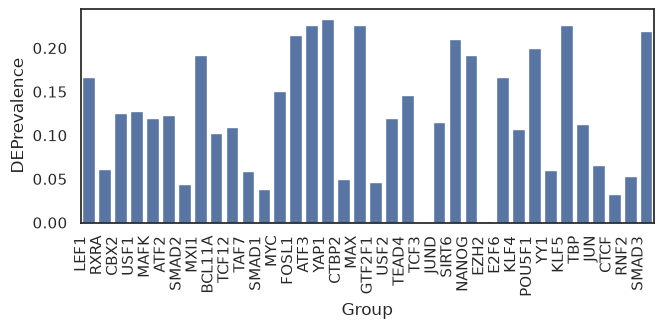

In [16]:
plt.figure(figsize=(7, 3))

sns.set(style='white')
# Base barplot
ax = sns.barplot(
    data=df1,
    x="Group",
    y="DEPrevalence"
)

plt.tight_layout()
plt.xticks(rotation=90, ha='right')
plt.savefig("perturb_orf_mche_bar_deprevalence.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()